# 스프린트 미션7 | SSD 모델로 개와 고양이의 얼굴(Face) 영역 감지 #

#### SSD 모델을 활용하여 개와 고양이의 얼굴(Face) 영역을 감지하는 Object Detection 작업 ####

### 목차 ###

0. 서론
1. 데이터 준비하기
2. 데이터셋 준비
3. 데이터 학습 준비
4. 모델 평가
5. YOLO모델 사용해보기
6. 모델 평가
7. 프로젝트 종합 평가

## 0. 서론 ##

 이번 미션에서는 SD 모델을 활용하여 개와 고양이의 얼굴(Face) 영역을 감지하는 Object Detection 작업을 수행한다.


**데이터 소개**
 - The Oxford-IIIT Pet Dataset
  - annotations(xml): 각 이미지 파일에 대한 annotation
  - images: 이미지 파일(37종의 개와 고양이)

**생각해보자**
어떤 모델을 사용하는 것이 좋을까?
 - SSD-300
 - SSD-500
 - SSD-resnet
  -> SSD-300으로 결정 : 동물 얼굴이 인식하기 힘들게 구성된것 같지는 않아 보여서 300으로 진행하고, 대신 epochs값을 여러가지 시도해보겠다.

## 1. 데이터 준비하기 ##

### 1-1. 데이터 불러오기 ###
-> Kaggle에서 The Oxford-IIIT Pet Dataset을 다운받는다.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zippyz/cats-and-dogs-breeds-classification-oxford-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cats-and-dogs-breeds-classification-oxford-dataset' dataset.
Path to dataset files: /kaggle/input/cats-and-dogs-breeds-classification-oxford-dataset


### 1-2. GPU 설정하기 ###
-> Colab GPU와 연결한다.

In [ ]:
import torch

# GPU 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level < 2:  # 너무 깊이 들어가지 않도록 2단계까지만
        subindent = ' ' * 2 * (level + 1)
        for file in files[:5]:  # 파일은 5개만 샘플로 출력
            print(f'{subindent}{file}')

cats-and-dogs-breeds-classification-oxford-dataset/
  annotations/
    annotations/
      xmls/
      trimaps/
  images/
    images/


### 1-3. 데이터 파일 경로 설정 및 개수 확인 ###
-> 다운로드한 데이터 파일의 경로를 설정하고, 각각 데이터의 개수를 확인한다.

In [ ]:
import pandas as pd
import os
import cv2
import matplotlib.pyplot as plt

# 파일 경로 설정
trainval_file_path = os.path.join(path, "annotations", "annotations", "trainval.txt")
test_file_path = os.path.join(path, "annotations", "annotations", "test.txt")

# 이미지, Annotation 경로 설정
image_dir = os.path.join(path, "images", "images")
xml_dir = os.path.join(path, "annotations", "annotations", "xmls")

# Train/Validation 파일 읽기
df_trainval = pd.read_csv(trainval_file_path, sep="\s+", header=None)
df_trainval.columns = ["Image", "ClassID", "Species", "BreedID"]

# Test 파일 읽기
df_test = pd.read_csv(test_file_path, sep="\s+", header=None)
df_test.columns = ["Image", "ClassID", "Species", "BreedID"]

# 데이터 크기 확인
print(f"Train/Validation 데이터 수: {len(df_trainval)}")
print(f"Test 데이터 수: {len(df_test)}")

# Annotation 개수 확인
xml_files = [file for file in os.listdir(xml_dir) if file.endswith(".xml")]
print(f"XML 파일 개수: {len(xml_files)}")

<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:19: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_534/3296508719.py:15: SyntaxWarning: invalid escape sequence '\s'
  df_trainval = pd.read_csv(trainval_file_path, sep="\s+", header=None)
/tmp/ipykernel_534/3296508719.py:19: SyntaxWarning: invalid escape sequence '\s'
  df_test = pd.read_csv(test_file_path, sep="\s+", header=None)


Train/Validation 데이터 수: 3680
Test 데이터 수: 3669
XML 파일 개수: 3686


Train/Validation 데이터 수는 3680, XML 파일 개수 3686개로 다르게 나왔다. 추후 데이터 학습 전 다시 확인해보자.

### 1-4. 데이터 세부 구성 확인 ###
-> 데이터들이 어떻게 구성되어 있는지 확인한다.

In [ ]:
print(df_trainval.shape)
df_trainval.head()

(3680, 4)


,Image,ClassID,Species,BreedID
0,Abyssinian_100,1,1,1
1,Abyssinian_101,1,1,1
2,Abyssinian_102,1,1,1
3,Abyssinian_103,1,1,1
4,Abyssinian_104,1,1,1


In [ ]:
print(df_test.shape)
df_test.head()

(3669, 4)


,Image,ClassID,Species,BreedID
0,Abyssinian_201,1,1,1
1,Abyssinian_202,1,1,1
2,Abyssinian_204,1,1,1
3,Abyssinian_205,1,1,1
4,Abyssinian_206,1,1,1


In [ ]:
df_test['Species'].value_counts()

,count
Species,
2,2486
1,1183


In [ ]:
df_test['Species'].value_counts()

,count
Species,
2,2486
1,1183


In [ ]:
import xml.etree.ElementTree as ET

# XML 파일 하나 샘플로 읽기
sample_xml = os.path.join(xml_dir, xml_files[0])
tree = ET.parse(sample_xml)
root = tree.getroot()

# XML 내용 출력
for child in root:
    print(child.tag, child.text)
    for subchild in child:
        print(f"  {subchild.tag}: {subchild.text}")

folder OXIIIT
filename staffordshire_bull_terrier_165.jpg
source None
  database: OXFORD-IIIT Pet Dataset
  annotation: OXIIIT
  image: flickr
size None
  width: 500
  height: 375
  depth: 3
segmented 0
object None
  name: dog
  pose: Frontal
  truncated: 0
  occluded: 0
  bndbox: None
  difficult: 0


### 1-5. 데이터 이미지 확인하가 ###
-> 데이터에 들어있는 이미지를 출력해서 확인한다.

In [ ]:
# Train과 Validation에 사용될 이미지 파일 이름 리스트 생성
trainval_list = df_trainval['Image'].tolist()

# Test에 사용될 이미지 파일 이름 리스트 생성
test_list = df_test['Image'].tolist()

##### Train 데이터에서 이미지 불러오기 ####

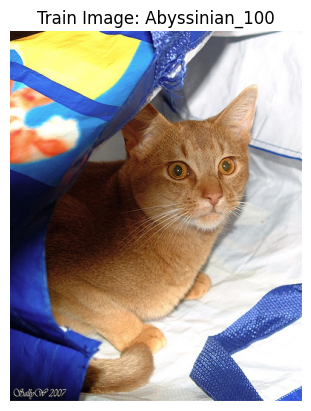

In [ ]:
# Train 데이터에서 예제 이미지 불러오기
train_example_image_name = df_trainval["Image"].iloc[0]
train_image_path = os.path.join(image_dir, f"{train_example_image_name}.jpg")

# 이미지 읽기
train_image = cv2.imread(train_image_path)
train_image = cv2.cvtColor(train_image, cv2.COLOR_BGR2RGB)

# Train 이미지 출력
plt.imshow(train_image)
plt.title(f"Train Image: {train_example_image_name}")
plt.axis("off")
plt.show()

##### Test 데이터에서 이미지 불러오기 ####

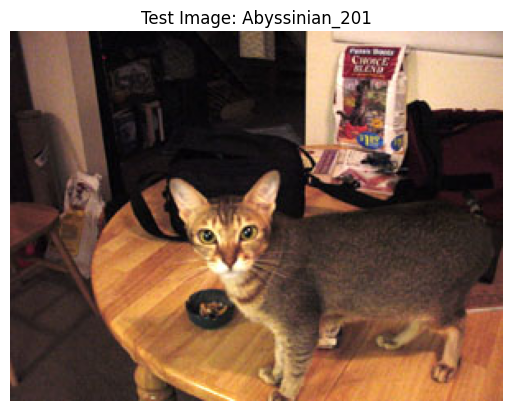

In [ ]:
# Test 데이터에서 예제 이미지 불러오기
test_example_image_name = df_test["Image"].iloc[0]
test_image_path = os.path.join(image_dir, f"{test_example_image_name}.jpg")

# 이미지 읽기
test_image = cv2.imread(test_image_path)
test_image = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB)

# Test 이미지 출력
plt.imshow(test_image)
plt.title(f"Test Image: {test_example_image_name}")
plt.axis("off")
plt.show()

### 1-6. XML 파일이 없는 Train 이미지 수 확인 ###
-> 위에서 데이터를 가져올 때 Train/val 데이터 수와 XML 데이터 수가 맞지 않았다.

-> 데이터 목록 중 XML파일이 없는 이미지를 확인하는 과정이다.

In [ ]:
# XML 파일 이름 가져오기 (확장자 제거)
xml_list = [os.path.splitext(file)[0] for file in os.listdir(xml_dir) if file.endswith(".xml")]

# Train 이미지에 대해 XML 파일이 없는 경우 확인
missing_xml = [image for image in trainval_list if image not in xml_list]

# Train 이미지에 대해 XML 파일이 있는 경우 확인
trainval_list = [image for image in trainval_list if image in xml_list]

# 결과 출력
print(f"XML 파일이 없는 Train 이미지 수: {len(missing_xml)}")
print(missing_xml)

XML 파일이 없는 Train 이미지 수: 9
['Abyssinian_104', 'Bengal_111', 'samoyed_10', 'Bengal_175', 'Egyptian_Mau_14', 'Egyptian_Mau_156', 'Egyptian_Mau_186', 'Ragdoll_199', 'saint_bernard_15']


### 1-7. XML 재귀 출력 ###
-> 중첩된 XML 요소(부모-자식)를 처리하기 위해 함수가 자기 자신을 호출하여 트리 구조의 데이터를 순회/출력한다.

In [ ]:
import xml.etree.ElementTree as ET

# 예제 XML 파일 경로
example_xml_file = os.path.join(xml_dir, xml_files[0])

# XML 파일 읽기 및 파싱
tree = ET.parse(example_xml_file)
root = tree.getroot()

# 재귀적으로 모든 태그와 데이터 출력 함수
def print_all_elements(element, indent=""):
    print(f"{indent}{element.tag}: {element.text}")
    for child in element:
        print_all_elements(child, indent + "  ")

# XML 구조 탐색
print_all_elements(root)

annotation: None
  folder: OXIIIT
  filename: staffordshire_bull_terrier_165.jpg
  source: None
    database: OXFORD-IIIT Pet Dataset
    annotation: OXIIIT
    image: flickr
  size: None
    width: 500
    height: 375
    depth: 3
  segmented: 0
  object: None
    name: dog
    pose: Frontal
    truncated: 0
    occluded: 0
    bndbox: None
      xmin: 165
      ymin: 73
      xmax: 356
      ymax: 235
    difficult: 0


### 1-8. 단일 XML에서 1개 샘플 추출 ###
-> XML 구조가 원하는 형태가 맞는지 확인한다.

In [ ]:
# XML 파일에서 Bounding Box와 클래스 정보 추출
for obj in root.findall("object"):
    class_name = obj.find("name").text  # 클래스 이름
    bndbox = obj.find("bndbox")
    x_min = int(bndbox.find("xmin").text)
    y_min = int(bndbox.find("ymin").text)
    x_max = int(bndbox.find("xmax").text)
    y_max = int(bndbox.find("ymax").text)

    print(f"Class: {class_name}, Bounding Box: ({x_min}, {y_min}, {x_max}, {y_max})")

Class: dog, Bounding Box: (165, 73, 356, 235)


### 1-9. 모든 XML을 읽어 annotations 리스트 구축 ###
-> 데이터셋의 모든 라벨을 모아서 학습용 메타데이터를 만든다.
-> XML전체를 파싱해 바로 쓰거나, 전처리/검증/통계에 쓰기 위한 라벨 테이블(리스트)를 만드는 과정이다.

In [ ]:
# 모든 XML 파일 처리
annotations = []

for xml_file in xml_files:
    xml_path = os.path.join(xml_dir, xml_file)
    tree = ET.parse(xml_path)
    root = tree.getroot()

    image_name = root.find("filename").text  # 이미지 파일 이름

    for obj in root.findall("object"):
        class_name = obj.find("name").text
        bndbox = obj.find("bndbox")
        x_min = int(bndbox.find("xmin").text)
        y_min = int(bndbox.find("ymin").text)
        x_max = int(bndbox.find("xmax").text)
        y_max = int(bndbox.find("ymax").text)

        annotations.append({
            "image": image_name,
            "class": class_name,
            "bbox": [x_min, y_min, x_max, y_max]
        })

### 1-10. Object Detection 시각화 ###
-> 1-9에서 XML 파싱의 결과가 진짜 이미지와 매칭되는지 테스트한다.

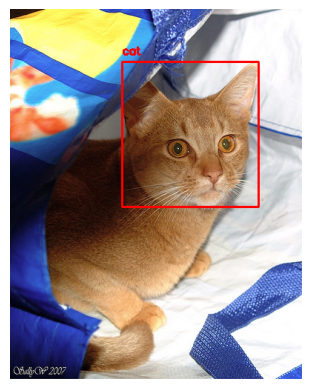

In [ ]:
# Train 데이터에서 예제 이미지 불러오기
train_example_image_name = df_trainval["Image"].iloc[0]
train_image_path = os.path.join(image_dir, f"{train_example_image_name}.jpg")

# 이미지 읽기
image = cv2.imread(train_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# 해당 이미지의 어노테이션 가져오기
annotations = [anno for anno in annotations if anno["image"] == f"{train_example_image_name}.jpg"]

# Bounding Box 그리기
for anno in annotations:
    x_min, y_min, x_max, y_max = anno["bbox"]
    cv2.rectangle(image, (x_min, y_min), (x_max, y_max), (255, 0, 0), 2)  # 빨간색 박스
    cv2.putText(image, anno["class"], (x_min, y_min - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

# 시각화
plt.imshow(image)
plt.axis("off")
plt.show()

## 2. 데이터셋 준비 ##

### 2-1. 데이터 전처리(transform) 파이프라인 정의 ###
-> 이미지 타입을 float32로 변환한다.
-> scale을 변환시켜 0~1 범위로 자동 스케일링 된다. (unit8일 경우 0~255이지만, float32로 변환한 상태라 0~1범위가 된다.)

In [ ]:
from torchvision.transforms import v2

# Train용 Transform (데이터 증강 포함)
train_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((300, 300)),           # SSD 입력 크기
    v2.RandomHorizontalFlip(p=0.5),  # 데이터 증강
    v2.ToDtype(dtype=torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ImageNet 정규화
])

# Validation / Test용 Transform (증강 없이)
val_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((300, 300)),
    v2.ToDtype(dtype=torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


### 2-2. PyTorch Object Detection 학습용 형태로 반환 ###
-> VOC(XML) 형식의 바운딩박스 라벨을 읽어서, PyTorch Object Detection 학습용 (image, target) 형태로 반환하는 커스텀 Dataset이다.

 - XML(VOC) 라벨을 읽어 detection 학습용 정답(target)을 구성

 - DataLoader로 쉽게 배치 학습 가능하게 만들기

 - SSD 학습에 필요한 데이터 형태로 통일

In [ ]:
from PIL import Image
from torch.utils.data import Dataset

class VOCDataset(Dataset):
    def __init__(self, image_dir, annotation_dir, classes, image_list, transforms=None):
        self.image_dir = image_dir
        self.annotation_dir = annotation_dir
        self.classes = classes
        self.transforms = transforms
        self.image_files = image_list # 미리 필터링된 유효한 이미지 파일 리스트

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        # 이미지 및 XML 파일 경로 설정
        image_file = self.image_files[idx] + ".jpg"
        annotation_file = self.image_files[idx] + ".xml"
        image_path = os.path.join(self.image_dir, image_file)
        annotation_path = os.path.join(self.annotation_dir, annotation_file)

        # 이미지 로드
        image = Image.open(image_path).convert("RGB") # RGB 형식으로 이미지 받음

        # 어노테이션 로드
        boxes = []
        labels = []
        tree = ET.parse(annotation_path)
        root = tree.getroot()

        for obj in root.findall("object"):
            class_name = obj.find("name").text
            if class_name not in self.classes:
                continue
            labels.append(self.classes.index(class_name))

            bndbox = obj.find("bndbox")
            x_min = int(bndbox.find("xmin").text)
            y_min = int(bndbox.find("ymin").text)
            x_max = int(bndbox.find("xmax").text)
            y_max = int(bndbox.find("ymax").text)
            boxes.append([x_min, y_min, x_max, y_max])

        # Tensor로 변환
        boxes = torch.tensor(boxes, dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.int64)

        # Transform 적용
        if self.transforms:
            image, boxes, labels = self.transforms(image, boxes, labels)

        target = {"boxes": boxes, "labels": labels}
        return image, target

### 2-3. test 이미지들을 순서대로 불러와 모델에 넣기 좋은 형태로 반환 ###
->

In [ ]:
class TestDataset(Dataset):
    def __init__(self, image_dir, image_list, transforms=None):
        self.image_dir = image_dir
        self.transforms = transforms
        self.image_files = image_list  # 테스트 이미지 리스트 (확장자 없음)

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        # 이미지 파일 경로
        image_file = self.image_files[idx] + ".jpg"
        image_path = os.path.join(self.image_dir, image_file)

        # 이미지 로드
        image = Image.open(image_path).convert("RGB")

        # Transform 적용
        if self.transforms:
            image = self.transforms(image)

        return image, self.image_files[idx]  # 이미지와 파일 이름 반환

In [ ]:
import os
import torch
import xml.etree.ElementTree as ET
from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms import v2
from torchvision.transforms.v2 import functional as F
from torchvision import tv_tensors


# -----------------------------
# 1) Letterbox Transform (비율 유지 + 패딩 → 300x300)
# -----------------------------
class LetterboxResize300:
    def __init__(self, size=300, fill=0):
        self.size = size
        self.fill = fill

    def __call__(self, image, target=None):
        # PIL → tv_tensor 변환
        image = v2.ToImage()(image)

        # 원본 크기
        h, w = F.get_size(image)

        # 긴 변 기준 스케일 계산
        scale = self.size / max(h, w)
        new_h = int(round(h * scale))
        new_w = int(round(w * scale))

        # 리사이즈
        image = F.resize(image, (new_h, new_w), antialias=True)

        # 패딩 계산 (가운데 정렬)
        pad_h = self.size - new_h
        pad_w = self.size - new_w
        pad_top    = pad_h // 2
        pad_bottom = pad_h - pad_top
        pad_left   = pad_w // 2
        pad_right  = pad_w - pad_left

        # 패딩 적용
        image = F.pad(image, [pad_left, pad_top, pad_right, pad_bottom], fill=self.fill)

        # target이 없으면 (Test용) image만 반환
        if target is None:
            return image

        # Bounding Box에도 동일 변환 적용
        boxes = target["boxes"].clone()

        # scale 적용
        boxes = boxes * torch.tensor([scale, scale, scale, scale], dtype=boxes.dtype)

        # pad offset 적용
        boxes = boxes + torch.tensor([pad_left, pad_top, pad_left, pad_top], dtype=boxes.dtype)

        # BoundingBoxes 재정의 (300x300 캔버스 기준)
        boxes = tv_tensors.BoundingBoxes(
            boxes,
            format="XYXY",
            canvas_size=(self.size, self.size)
        )

        target = dict(target)
        target["boxes"] = boxes

        return image, target


# -----------------------------
# 2) Train/Val용 Dataset
# -----------------------------
class VOCDataset(Dataset):
    def __init__(self, image_dir, annotation_dir, classes, image_list, transforms=None):
        self.image_dir = image_dir
        self.annotation_dir = annotation_dir
        self.classes = classes
        self.transforms = transforms
        self.image_files = image_list

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_id = self.image_files[idx]
        image_path = os.path.join(self.image_dir, f"{image_id}.jpg")
        annotation_path = os.path.join(self.annotation_dir, f"{image_id}.xml")

        # 이미지 로드
        image = Image.open(image_path).convert("RGB")
        w, h = image.size  # PIL은 (W, H) 순서

        # XML 파싱
        boxes = []
        labels = []
        tree = ET.parse(annotation_path)
        root = tree.getroot()

        for obj in root.findall("object"):
            class_name = obj.find("name").text
            if class_name not in self.classes:
                continue

            # background를 0으로 두고, cat=1, dog=2
            label = self.classes.index(class_name) + 1
            labels.append(label)

            bndbox = obj.find("bndbox")
            x_min = int(bndbox.find("xmin").text)
            y_min = int(bndbox.find("ymin").text)
            x_max = int(bndbox.find("xmax").text)
            y_max = int(bndbox.find("ymax").text)
            boxes.append([x_min, y_min, x_max, y_max])

        # 텐서 변환
        boxes  = torch.tensor(boxes, dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.int64)

        # 빈 박스 방어 처리
        if boxes.numel() == 0:
            boxes  = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)

        # BoundingBoxes로 감싸기 (원본 캔버스 기준)
        boxes = tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=(h, w))
        target = {"boxes": boxes, "labels": labels}

        # Transform 적용 (image + target 함께)
        if self.transforms:
            image, target = self.transforms(image, target)

        # float32 변환
        image = v2.ToDtype(torch.float32, scale=True)(image)

        return image, target


# -----------------------------
# 3) Test용 Dataset
# -----------------------------
class TestDataset(Dataset):
    def __init__(self, image_dir, image_list, transforms=None):
        self.image_dir = image_dir
        self.transforms = transforms
        self.image_files = image_list

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_id = self.image_files[idx]
        image_path = os.path.join(self.image_dir, f"{image_id}.jpg")

        image = Image.open(image_path).convert("RGB")

        # Transform 적용 (image만)
        if self.transforms:
            image = self.transforms(image)

        # float32 변환
        image = v2.ToDtype(torch.float32, scale=True)(v2.ToImage()(image))

        return image, image_id


# -----------------------------
# 4) Transform 및 Dataset 인스턴스 생성
# -----------------------------
letterbox = LetterboxResize300(size=300, fill=0)

train_dataset = VOCDataset(
    image_dir=image_dir,
    annotation_dir=xml_dir,
    classes=["cat", "dog"],
    image_list=trainval_list,
    transforms=letterbox
)

test_dataset = TestDataset(
    image_dir=image_dir,
    image_list=test_list,
    transforms=letterbox
)

print(f"Train Dataset 크기: {len(train_dataset)}")
print(f"Test Dataset 크기: {len(test_dataset)}")

Train Dataset 크기: 3671
Test Dataset 크기: 3669


In [ ]:
from PIL import Image
import os
from collections import Counter

def get_image_sizes(image_dir, image_list, sample_n=None):
    """
    image_list: 확장자 없는 파일 이름 리스트 (예: 'Abyssinian_100')
    sample_n: None이면 전체, 숫자면 앞에서부터 sample_n개만 검사
    """
    if sample_n is not None:
        image_list = image_list[:sample_n]

    sizes = []
    missing = []

    for name in image_list:
        img_path = os.path.join(image_dir, f"{name}.jpg")
        if not os.path.exists(img_path):
            missing.append(name)
            continue

        with Image.open(img_path) as img:
            w, h = img.size  # (width, height)
        sizes.append((w, h))

    return sizes, missing

def summarize_sizes(sizes, title=""):
    if not sizes:
        print(f"[{title}] 이미지가 없습니다.")
        return

    counter = Counter(sizes)
    widths = [w for w, h in sizes]
    heights = [h for w, h in sizes]

    print(f"\n[{title}]")
    print(f"- 총 이미지 수: {len(sizes)}")
    print(f"- 고유 해상도 개수: {len(counter)}")
    print(f"- width  최소/최대: {min(widths)} / {max(widths)}")
    print(f"- height 최소/최대: {min(heights)} / {max(heights)}")
    print("- 가장 많은 해상도 Top 10:")
    for (w, h), cnt in counter.most_common(10):
        print(f"  {w}x{h}: {cnt}")

# ===== 사용 예시 =====
# trainval_list, test_list, image_dir가 이미 정의되어 있다고 가정합니다.

train_sizes, train_missing = get_image_sizes(image_dir, trainval_list, sample_n=None)  # 전체 검사
test_sizes, test_missing   = get_image_sizes(image_dir, test_list, sample_n=None)      # 전체 검사

summarize_sizes(train_sizes, title="Train/Val")
if train_missing:
    print(f"- 누락된 Train/Val 이미지 파일 수: {len(train_missing)} (예: {train_missing[:10]})")

summarize_sizes(test_sizes, title="Test")
if test_missing:
    print(f"- 누락된 Test 이미지 파일 수: {len(test_missing)} (예: {test_missing[:10]})")


[Train/Val]
- 총 이미지 수: 3671
- 고유 해상도 개수: 705
- width  최소/최대: 114 / 3264
- height 최소/최대: 108 / 2606
- 가장 많은 해상도 Top 10:
  500x375: 768
  500x333: 488
  375x500: 250
  333x500: 221
  300x225: 201
  500x334: 123
  500x332: 74
  334x500: 66
  500x335: 40
  332x500: 39

[Test]
- 총 이미지 수: 3669
- 고유 해상도 개수: 651
- width  최소/최대: 137 / 1646
- height 최소/최대: 103 / 2160
- 가장 많은 해상도 Top 10:
  500x375: 654
  500x333: 581
  333x500: 288
  375x500: 261
  500x334: 127
  500x332: 111
  334x500: 85
  300x225: 60
  500x335: 57
  500x500: 57


In [ ]:
from sklearn.model_selection import train_test_split

# Train/Validation 분리 (trainval_list에서 70% Train, 30% Validation으로 나눔)
train_list, valid_list = train_test_split(trainval_list, test_size=0.3, random_state=42)  # 트레인, 벨리데이션 값 잘라주기

# 결과 확인
print(f"Train 이미지 수: {len(train_list)}")
print(f"Validation 이미지 수: {len(valid_list)}")
print(f"Test 이미지 수: {len(test_list)}")

Train 이미지 수: 2569
Validation 이미지 수: 1102
Test 이미지 수: 3669


In [ ]:
from torchvision.transforms import v2
from torchvision import tv_tensors
from torch.utils.data import DataLoader  # 추가

# -----------------------------
# 클래스 정의
# -----------------------------
classes = ["cat", "dog"]

# -----------------------------
# Train용 Transform (증강 포함)
# -----------------------------
class TrainTransform:
    def __init__(self, size=300, fill=0):
        self.letterbox = LetterboxResize300(size=size, fill=fill)

        self.augment = v2.Compose([
            v2.RandomHorizontalFlip(p=0.5),
            v2.RandomPhotometricDistort(
                brightness=(0.8, 1.2),
                contrast=(0.8, 1.2),
                saturation=(0.8, 1.2),
                hue=(-0.1, 0.1),
                p=0.5
            ),
            v2.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.2,
                hue=0.05
            ),
        ])

    def __call__(self, image, target=None):
        if target is not None:
            image, target = self.letterbox(image, target)
        else:
            image = self.letterbox(image)

        if target is not None:
            image, target["boxes"] = self.augment(image, target["boxes"])
        else:
            image = self.augment(image)

        if target is not None:
            return image, target
        return image


# -----------------------------
# Val / Test용 Transform
# -----------------------------
val_transform = LetterboxResize300(size=300, fill=0)

# -----------------------------
# Dataset 인스턴스 생성
# -----------------------------
train_transform = TrainTransform(size=300, fill=0)

train_dataset = VOCDataset(
    image_dir=image_dir,
    annotation_dir=xml_dir,
    classes=classes,
    image_list=train_list,
    transforms=train_transform
)

valid_dataset = VOCDataset(
    image_dir=image_dir,
    annotation_dir=xml_dir,
    classes=classes,
    image_list=valid_list,
    transforms=val_transform
)

test_dataset = TestDataset(
    image_dir=image_dir,
    image_list=test_list,
    transforms=val_transform
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True,  collate_fn=lambda x: tuple(zip(*x)))
val_loader   = DataLoader(valid_dataset, batch_size=8, shuffle=False, collate_fn=lambda x: tuple(zip(*x)))
test_loader  = DataLoader(test_dataset,  batch_size=8, shuffle=False, collate_fn=lambda x: tuple(zip(*x)))

print(f"Train 데이터셋 크기: {len(train_dataset)}")
print(f"Validation 데이터셋 크기: {len(valid_dataset)}")
print(f"Test 데이터셋 크기: {len(test_dataset)}")

Train 데이터셋 크기: 2569
Validation 데이터셋 크기: 1102
Test 데이터셋 크기: 3669


## 3. 데이터 학습 준비 ##

### 3-1. SSD 모델 준비 ###

In [ ]:
import torchvision
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

def build_ssd_model(num_classes, device):
    """
    num_classes: background 포함한 전체 클래스 수
                 (cat, dog 2개 → background 포함 3)
    """
    # 사전학습 가중치로 SSD300 로드
    weights = SSD300_VGG16_Weights.COCO_V1
    model = ssd300_vgg16(weights=weights)

    # Classification Head만 교체 (norm_layer 제거)
    in_channels = [512, 1024, 512, 256, 256, 256]
    num_anchors = model.anchor_generator.num_anchors_per_location()

    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels,
        num_anchors=num_anchors,
        num_classes=num_classes
    )

    model = model.to(device)
    return model

# num_classes = background(1) + cat(1) + dog(1) = 3
num_classes = len(classes) + 1  # 3
model = build_ssd_model(num_classes=num_classes, device=device)

print(f"총 파라미터 수: {sum(p.numel() for p in model.parameters()):,}")
print(f"학습 가능한 파라미터 수: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 195MB/s] 


총 파라미터 수: 23,879,570
학습 가능한 파라미터 수: 23,840,850


### 3-2. Optimizer & Scheduler 설정 ###


In [ ]:
def train_one_epoch(model, optimizer, data_loader, device):
    model.train()
    total_loss = 0.0

    for images, targets in data_loader:
        images = [normalize(img.to(device)) for img in images]

        # BoundingBoxes → 일반 Tensor로 변환
        new_targets = []
        for t in targets:
            new_targets.append({
                "boxes":  t["boxes"].data.to(device) if hasattr(t["boxes"], "data") else t["boxes"].to(device),
                "labels": t["labels"].to(device)
            })

        loss_dict = model(images, new_targets)
        losses = sum(loss for loss in loss_dict.values())

        if torch.isnan(losses):
            print("⚠️ nan loss 감지, 해당 배치 스킵")
            continue

        optimizer.zero_grad()
        losses.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        total_loss += losses.item()

    return total_loss / len(data_loader)


def evaluate(model, data_loader, device):
    model.train()
    total_loss = 0.0

    with torch.no_grad():
        for images, targets in data_loader:
            images = [normalize(img.to(device)) for img in images]

            new_targets = []
            for t in targets:
                new_targets.append({
                    "boxes":  t["boxes"].data.to(device) if hasattr(t["boxes"], "data") else t["boxes"].to(device),
                    "labels": t["labels"].to(device)
                })

            loss_dict = model(images, new_targets)
            losses = sum(loss for loss in loss_dict.values())

            if torch.isnan(losses):
                continue

            total_loss += losses.item()

    return total_loss / len(data_loader)

### 3-3. 모델 학습하기 ###


[Epoch 01/30] Train Loss: 3.9718 | Val Loss: 2.3013 | LR: 0.001000
 Best 모델 저장 (Val Loss: 2.3013)
[Epoch 02/30] Train Loss: 1.8288 | Val Loss: 1.7123 | LR: 0.001000
 Best 모델 저장 (Val Loss: 1.7123)
[Epoch 03/30] Train Loss: 1.4619 | Val Loss: 1.5599 | LR: 0.001000
 Best 모델 저장 (Val Loss: 1.5599)
[Epoch 04/30] Train Loss: 1.2638 | Val Loss: 1.5146 | LR: 0.001000
 Best 모델 저장 (Val Loss: 1.5146)
[Epoch 05/30] Train Loss: 1.0990 | Val Loss: 1.4338 | LR: 0.001000
 Best 모델 저장 (Val Loss: 1.4338)
[Epoch 06/30] Train Loss: 0.9901 | Val Loss: 1.3523 | LR: 0.001000
 Best 모델 저장 (Val Loss: 1.3523)
[Epoch 07/30] Train Loss: 0.8949 | Val Loss: 1.3752 | LR: 0.001000
[Epoch 08/30] Train Loss: 0.8128 | Val Loss: 1.3658 | LR: 0.001000
[Epoch 09/30] Train Loss: 0.7487 | Val Loss: 1.3520 | LR: 0.001000
 Best 모델 저장 (Val Loss: 1.3520)
[Epoch 10/30] Train Loss: 0.7076 | Val Loss: 1.3393 | LR: 0.000100
 Best 모델 저장 (Val Loss: 1.3393)
[Epoch 11/30] Train Loss: 0.5380 | Val Loss: 1.2791 | LR: 0.000100
 Best 모델 저장 (Va

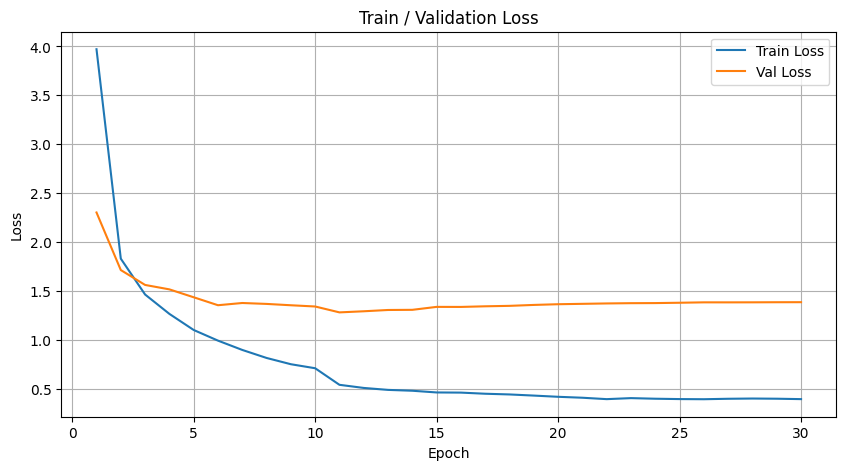

In [ ]:
from torchvision.transforms import v2
import torch.optim as optim

# -----------------------------
# 1) Normalize 정의
# -----------------------------
normalize = v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# -----------------------------
# 2) Train 함수
# -----------------------------
def train_one_epoch(model, optimizer, data_loader, device):
    model.train()
    total_loss = 0.0

    for images, targets in data_loader:
        images = [normalize(img.to(device)) for img in images]

        new_targets = []
        for t in targets:
            new_targets.append({
                "boxes":  t["boxes"].data.to(device) if hasattr(t["boxes"], "data") else t["boxes"].to(device),
                "labels": t["labels"].to(device)
            })

        loss_dict = model(images, new_targets)
        losses = sum(loss for loss in loss_dict.values())

        if torch.isnan(losses):
            print("⚠️ nan loss 감지, 해당 배치 스킵")
            continue

        optimizer.zero_grad()
        losses.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        total_loss += losses.item()

    return total_loss / len(data_loader)

# -----------------------------
# 3) Validation 함수
# -----------------------------
def evaluate(model, data_loader, device):
    model.train()
    total_loss = 0.0

    with torch.no_grad():
        for images, targets in data_loader:
            images = [normalize(img.to(device)) for img in images]

            new_targets = []
            for t in targets:
                new_targets.append({
                    "boxes":  t["boxes"].data.to(device) if hasattr(t["boxes"], "data") else t["boxes"].to(device),
                    "labels": t["labels"].to(device)
                })

            loss_dict = model(images, new_targets)
            losses = sum(loss for loss in loss_dict.values())

            if torch.isnan(losses):
                continue

            total_loss += losses.item()

    return total_loss / len(data_loader)

# -----------------------------
# 4) 모델 재초기화
# -----------------------------
model = build_ssd_model(num_classes=num_classes, device=device)

# -----------------------------
# 5) Optimizer & Scheduler
# -----------------------------
optimizer = optim.SGD(
    model.parameters(),
    lr=0.001,
    momentum=0.9,
    weight_decay=5e-4
)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

# -----------------------------
# 6) 학습 루프
# -----------------------------
num_epochs = 30
best_val_loss = float("inf")
train_loss_list = []
val_loss_list   = []

for epoch in range(num_epochs):
    train_loss = train_one_epoch(model, optimizer, train_loader, device)
    val_loss   = evaluate(model, val_loader, device)
    scheduler.step()

    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)

    print(f"[Epoch {epoch+1:02d}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"LR: {scheduler.get_last_lr()[0]:.6f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_ssd_model.pth")
        print(f" Best 모델 저장 (Val Loss: {best_val_loss:.4f})")

# -----------------------------
# 7) Loss 시각화
# -----------------------------
plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs+1), train_loss_list, label="Train Loss")
plt.plot(range(1, num_epochs+1), val_loss_list,   label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train / Validation Loss")
plt.legend()
plt.grid(True)
plt.show()



## 4. 모델 평가 ##

### 4-1. mAP 평가 ###

예측 수집 중...

클래스                AP
----------------------
cat            0.9091
dog            0.9073
----------------------
mAP            0.9082


/tmp/ipykernel_534/2210450748.py:181: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/2210450748.py:181: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/2210450748.py:181: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/2210450748.py:181: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/2210450748.py:181: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/2210450748.py:181: UserWarning: Glyph 45813 (\N{HANGUL SYLLABLE DAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128309 (\N{LARGE BLUE CIRCLE}) missing from 

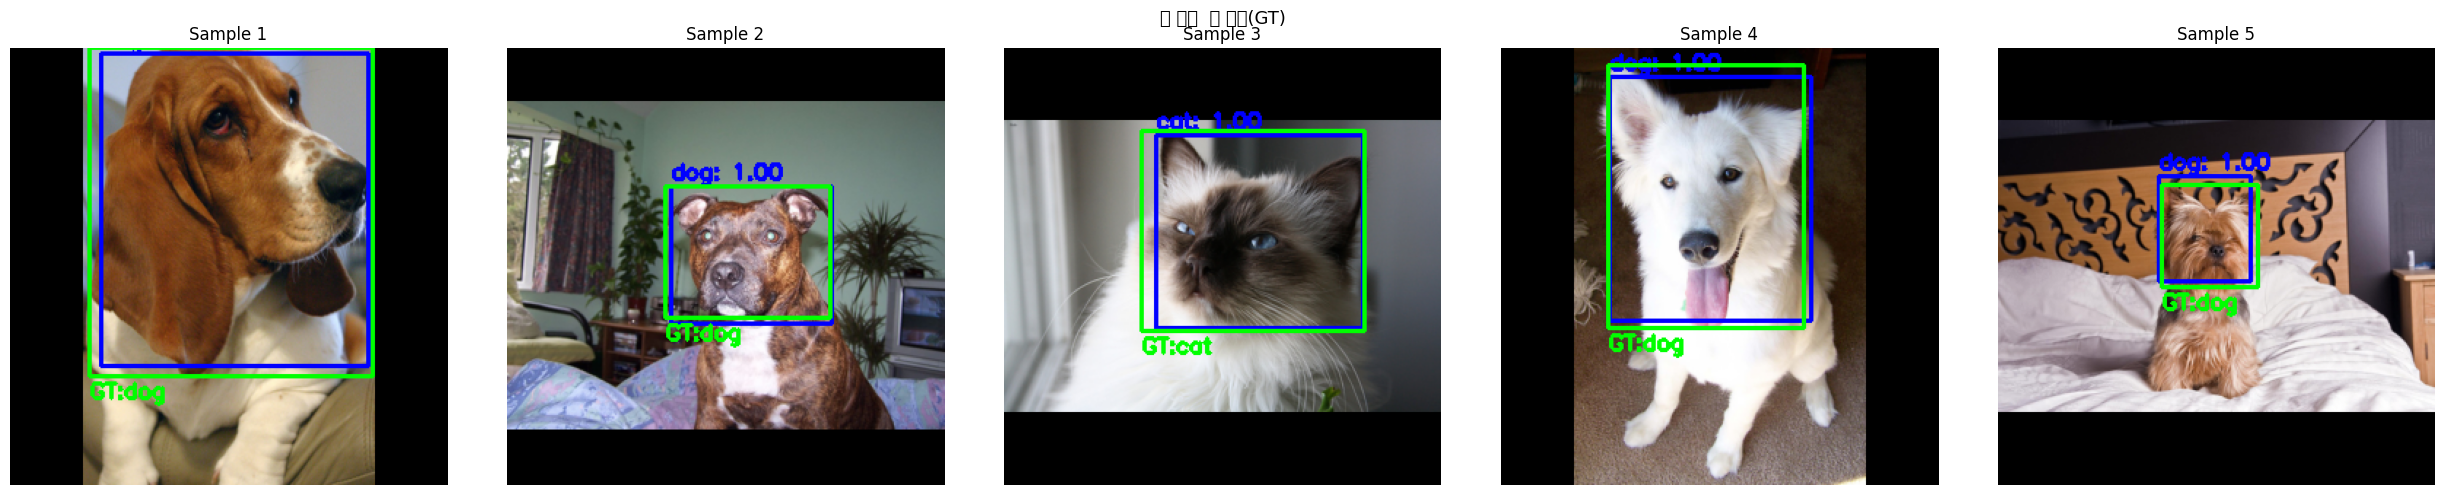

In [ ]:
import numpy as np

# -----------------------------
# 1) 예측 수집 함수
# -----------------------------
def get_predictions(model, data_loader, device, score_threshold=0.3):
    model.eval()
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = [normalize(img.to(device)) for img in images]
            outputs = model(images)

            for output, target in zip(outputs, targets):
                keep = output["scores"] >= score_threshold
                all_predictions.append({
                    "boxes":  output["boxes"][keep].cpu(),
                    "labels": output["labels"][keep].cpu(),
                    "scores": output["scores"][keep].cpu()
                })
                all_targets.append({
                    "boxes":  target["boxes"].data.cpu() if hasattr(target["boxes"], "data") else target["boxes"].cpu(),
                    "labels": target["labels"].cpu()
                })

    return all_predictions, all_targets


# -----------------------------
# 2) IoU 계산 함수
# -----------------------------
def calculate_iou(box, boxes):
    x_min = np.maximum(box[0], boxes[:, 0])
    y_min = np.maximum(box[1], boxes[:, 1])
    x_max = np.minimum(box[2], boxes[:, 2])
    y_max = np.minimum(box[3], boxes[:, 3])

    intersection = np.maximum(0, x_max - x_min) * np.maximum(0, y_max - y_min)
    box_area   = (box[2] - box[0]) * (box[3] - box[1])
    boxes_area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    union = box_area + boxes_area - intersection

    return intersection / (union + 1e-6)


# -----------------------------
# 3) AP 계산 함수
# -----------------------------
def calculate_ap(predictions, targets, class_idx, iou_threshold=0.5):
    tp_list     = []
    scores_list = []
    num_gt      = 0

    for pred, gt in zip(predictions, targets):
        pred_mask = pred["labels"] == class_idx
        gt_mask   = gt["labels"]  == class_idx

        pred_boxes  = pred["boxes"][pred_mask].numpy()
        pred_scores = pred["scores"][pred_mask].numpy()
        gt_boxes    = gt["boxes"][gt_mask].numpy()

        num_gt += len(gt_boxes)

        if len(pred_boxes) == 0:
            continue

        # gt가 없으면 전부 FP 처리 (버그 수정: _ 인덱스 오류 제거)
        if len(gt_boxes) == 0:
            for score in pred_scores:
                tp_list.append(0)
                scores_list.append(score)
            continue

        matched = np.zeros(len(gt_boxes), dtype=bool)

        # score 내림차순 정렬
        sorted_idx  = np.argsort(-pred_scores)
        pred_boxes  = pred_boxes[sorted_idx]
        pred_scores = pred_scores[sorted_idx]

        for box, score in zip(pred_boxes, pred_scores):
            ious    = calculate_iou(box, gt_boxes)
            max_idx = np.argmax(ious)

            if ious[max_idx] >= iou_threshold and not matched[max_idx]:
                tp_list.append(1)
                matched[max_idx] = True
            else:
                tp_list.append(0)
            scores_list.append(score)

    if len(scores_list) == 0 or num_gt == 0:
        return 0.0

    sorted_idx = np.argsort(-np.array(scores_list))
    tp_array   = np.array(tp_list)[sorted_idx]

    tp_cumsum = np.cumsum(tp_array)
    fp_cumsum = np.cumsum(1 - tp_array)
    precision = tp_cumsum / (tp_cumsum + fp_cumsum + 1e-6)
    recall    = tp_cumsum / (num_gt + 1e-6)

    # 11-point interpolation
    ap = 0.0
    for thr in np.linspace(0, 1, 11):
        prec = precision[recall >= thr]
        ap  += np.max(prec) if len(prec) > 0 else 0.0
    ap /= 11

    return ap


# -----------------------------
# 4) mAP 계산 함수
# -----------------------------
def calculate_map(predictions, targets, classes, iou_threshold=0.5):
    ap_list = []
    print(f"\n{'클래스':<12} {'AP':>8}")
    print("-" * 22)

    for class_idx, class_name in enumerate(classes, start=1):
        ap = calculate_ap(predictions, targets, class_idx, iou_threshold)
        ap_list.append(ap)
        print(f"{class_name:<12} {ap:>8.4f}")

    mAP = np.mean(ap_list)
    print("-" * 22)
    print(f"{'mAP':<12} {mAP:>8.4f}")
    return mAP


# -----------------------------
# 5) 예측 시각화 함수
# -----------------------------
def visualize_predictions(model, dataset, device, classes, num_images=5, score_threshold=0.3):
    model.eval()
    class_names = ["background"] + classes

    fig, axes = plt.subplots(1, num_images, figsize=(5 * num_images, 5))

    for i in range(num_images):
        image, target = dataset[i]
        img_input = normalize(image.to(device)).unsqueeze(0)

        with torch.no_grad():
            output = model(img_input)[0]

        # 시각화용 이미지 (정규화 역변환)
        img_vis = image.permute(1, 2, 0).numpy()
        img_vis = (img_vis - img_vis.min()) / (img_vis.max() - img_vis.min())
        img_vis = (img_vis * 255).astype(np.uint8).copy()

        # 예측 bbox (파란색)
        keep = output["scores"] >= score_threshold
        for box, label, score in zip(
            output["boxes"][keep].cpu().numpy(),
            output["labels"][keep].cpu().numpy(),
            output["scores"][keep].cpu().numpy()
        ):
            x1, y1, x2, y2 = map(int, box)
            cv2.rectangle(img_vis, (x1, y1), (x2, y2), (0, 0, 255), 2)
            text = f"{class_names[label]}: {score:.2f}"
            cv2.putText(img_vis, text, (x1, max(y1-5, 0)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)

        # 정답 bbox (초록색)
        gt_boxes = target["boxes"].data.numpy() if hasattr(target["boxes"], "data") else target["boxes"].numpy()
        for box, label in zip(gt_boxes, target["labels"].numpy()):
            x1, y1, x2, y2 = map(int, box)
            cv2.rectangle(img_vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(img_vis, f"GT:{class_names[label]}", (x1, min(y2+15, 299)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

        axes[i].imshow(img_vis)
        axes[i].axis("off")
        axes[i].set_title(f"Sample {i+1}")

    plt.suptitle("🔵 예측  🟢 정답(GT)", fontsize=13)
    plt.tight_layout()
    plt.show()


# -----------------------------
# 6) 실행
# -----------------------------
model.load_state_dict(torch.load("best_ssd_model.pth"))

print("예측 수집 중...")
predictions, targets_list = get_predictions(model, val_loader, device, score_threshold=0.3)

mAP = calculate_map(predictions, targets_list, classes=classes)

visualize_predictions(model, valid_dataset, device, classes=classes, num_images=5)



## 5. YOLO 사용해보기 ##

### 5-1.YOLO 사용을 위한 XML -> TXT 변환 ###

In [ ]:
import os
import shutil
from PIL import Image
import xml.etree.ElementTree as ET

# -----------------------------
# YOLO 클래스 정의
# -----------------------------
yolo_classes = ["cat", "dog"]

# -----------------------------
# YOLO 데이터 저장 폴더 생성
# -----------------------------
yolo_base_dir  = "/content/yolo_dataset"

yolo_train_img = os.path.join(yolo_base_dir, "images", "train")
yolo_val_img   = os.path.join(yolo_base_dir, "images", "val")
yolo_test_img  = os.path.join(yolo_base_dir, "images", "test")

yolo_train_lbl = os.path.join(yolo_base_dir, "labels", "train")
yolo_val_lbl   = os.path.join(yolo_base_dir, "labels", "val")
yolo_test_lbl  = os.path.join(yolo_base_dir, "labels", "test")

for d in [yolo_train_img, yolo_val_img, yolo_test_img,
          yolo_train_lbl, yolo_val_lbl, yolo_test_lbl]:
    os.makedirs(d, exist_ok=True)

print("✅ YOLO 폴더 생성 완료")

# -----------------------------
# XML → TXT 변환 함수
# -----------------------------
def xml_to_yolo_txt(image_id, image_dir, xml_dir, label_out_dir, img_out_dir, yolo_classes, has_label=True):
    image_path = os.path.join(image_dir, f"{image_id}.jpg")
    xml_path   = os.path.join(xml_dir,   f"{image_id}.xml")

    if not os.path.exists(image_path):
        return False

    if not has_label or not os.path.exists(xml_path):
        shutil.copy(image_path, os.path.join(img_out_dir, f"{image_id}.jpg"))
        return True

    with Image.open(image_path) as img:
        img_w, img_h = img.size

    tree = ET.parse(xml_path)
    root = tree.getroot()

    lines = []
    for obj in root.findall("object"):
        class_name = obj.find("name").text
        if class_name not in yolo_classes:
            continue

        class_idx = yolo_classes.index(class_name)

        bndbox = obj.find("bndbox")
        x_min = int(bndbox.find("xmin").text)
        y_min = int(bndbox.find("ymin").text)
        x_max = int(bndbox.find("xmax").text)
        y_max = int(bndbox.find("ymax").text)

        cx = (x_min + x_max) / 2 / img_w
        cy = (y_min + y_max) / 2 / img_h
        bw = (x_max - x_min) / img_w
        bh = (y_max - y_min) / img_h

        cx = max(0.0, min(1.0, cx))
        cy = max(0.0, min(1.0, cy))
        bw = max(0.0, min(1.0, bw))
        bh = max(0.0, min(1.0, bh))

        lines.append(f"{class_idx} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}")

    if not lines:
        return False

    txt_path = os.path.join(label_out_dir, f"{image_id}.txt")
    with open(txt_path, "w") as f:
        f.write("\n".join(lines))

    shutil.copy(image_path, os.path.join(img_out_dir, f"{image_id}.jpg"))
    return True


# -----------------------------
# Train / Val / Test 변환 실행
# -----------------------------
def convert_split(image_list, label_out_dir, img_out_dir, split_name, has_label=True):
    success, skip = 0, 0
    for image_id in image_list:
        result = xml_to_yolo_txt(
            image_id=image_id,
            image_dir=image_dir,
            xml_dir=xml_dir,
            label_out_dir=label_out_dir,
            img_out_dir=img_out_dir,
            yolo_classes=yolo_classes,
            has_label=has_label
        )
        if result:
            success += 1
        else:
            skip += 1
    print(f"[{split_name}] 변환 완료: {success}개 / 스킵: {skip}개")

convert_split(train_list, yolo_train_lbl, yolo_train_img, "Train", has_label=True)
convert_split(valid_list, yolo_val_lbl,   yolo_val_img,   "Val",   has_label=True)
convert_split(test_list,  yolo_test_lbl,  yolo_test_img,  "Test",  has_label=False)

print("\n✅ 전체 XML → TXT 변환 완료!")

# 샘플 확인
sample_txt = os.path.join(yolo_train_lbl, os.listdir(yolo_train_lbl)[0])
print(f"\n샘플 TXT 파일: {sample_txt}")
with open(sample_txt, "r") as f:
    print(f.read())

✅ YOLO 폴더 생성 완료
[Train] 변환 완료: 2569개 / 스킵: 0개
[Val] 변환 완료: 1102개 / 스킵: 0개
[Test] 변환 완료: 3669개 / 스킵: 0개

✅ 전체 XML → TXT 변환 완료!

샘플 TXT 파일: /content/yolo_dataset/labels/train/Bombay_176.txt
0 0.597032 0.332000 0.614155 0.540000


In [ ]:
# -----------------------------
# 8번 - YOLO yaml 설정 파일 작성
# -----------------------------

yaml_content = f"""
# YOLO 데이터셋 설정 파일

# 데이터셋 루트 경로
path: {yolo_base_dir}

# 이미지 경로 (path 기준 상대 경로)
train: images/train
val: images/val
test: images/test

# 클래스 수
nc: {len(yolo_classes)}

# 클래스 이름 (인덱스 순서대로)
# 0 = cat, 1 = dog
names: {yolo_classes}
"""

# yaml 파일 저장
yaml_path = os.path.join(yolo_base_dir, "pet_dataset.yaml")
with open(yaml_path, "w") as f:
    f.write(yaml_content.strip())

print(" ✅yaml 파일 저장 완료!")
print(f"저장 경로: {yaml_path}")
print("\n--- yaml 파일 내용 ---")
with open(yaml_path, "r") as f:
    print(f.read())

✅ yaml 파일 저장 완료!
저장 경로: /content/yolo_dataset/pet_dataset.yaml

--- yaml 파일 내용 ---
# YOLO 데이터셋 설정 파일

# 데이터셋 루트 경로
path: /content/yolo_dataset

# 이미지 경로 (path 기준 상대 경로)
train: images/train
val: images/val
test: images/test

# 클래스 수
nc: 2

# 클래스 이름 (인덱스 순서대로)
# 0 = cat, 1 = dog
names: ['cat', 'dog']


In [ ]:
# -----------------------------
# 6번 - YOLOv8 전이학습
# -----------------------------

# ultralytics 설치
!pip install ultralytics -q

from ultralytics import YOLO

# -----------------------------
# 1) 사전학습 YOLOv8 모델 로드
# (yolov8n = nano, 가장 가벼운 버전)
# -----------------------------
yolo_model = YOLO("yolov8n.pt")

# -----------------------------
# 2) 학습 실행
# -----------------------------
results = yolo_model.train(
    data=yaml_path,          # yaml 파일 경로
    epochs=30,               # 학습 epoch 수
    imgsz=300,               # 입력 이미지 크기 (SSD와 동일하게 300)
    batch=8,                 # 배치 크기
    patience=10,             # Early Stopping (10 epoch 동안 개선 없으면 종료)
    device=0,                # GPU 사용 (T4)
    project="/content/yolo_runs",  # 결과 저장 폴더
    name="pet_detection",    # 실험 이름
    pretrained=True,         # 사전학습 가중치 사용 (전이학습)
    optimizer="SGD",         # Optimizer
    lr0=0.001,               # 초기 Learning Rate
    momentum=0.9,            # SGD Momentum
    weight_decay=5e-4,       # Weight Decay
    augment=True,            # YOLO 내장 증강 사용
    verbose=True             # 학습 로그 출력
)

print("\n✅ YOLOv8 학습 완료!")
print(f"결과 저장 경로: /content/yolo_runs/pet_detection")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 79.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.21 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset/pet_dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fracti



## 6. 모델 평가 ##

### 6-1. YOLO 모델 평가 ###

✅ results.csv 로드 완료!
컬럼 목록: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
   epoch      time  train/box_loss  train/cls_loss  train/dfl_loss  \
0      1   44.5606         1.13572         2.84858         1.32086   
1      2   83.4591         1.04490         1.91557         1.25878   
2      3  122.0440         0.98266         1.44715         1.21216   
3      4  160.3560         0.95249         1.24858         1.19166   
4      5  198.7170         0.90960         1.17310         1.16709   

   metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
0               0.41330            0.54078           0.47634   
1               0.73975            0.77829           0.81991   
2               0.90234            0.87742           0.94092   
3               0.93457            0.89783           0.96

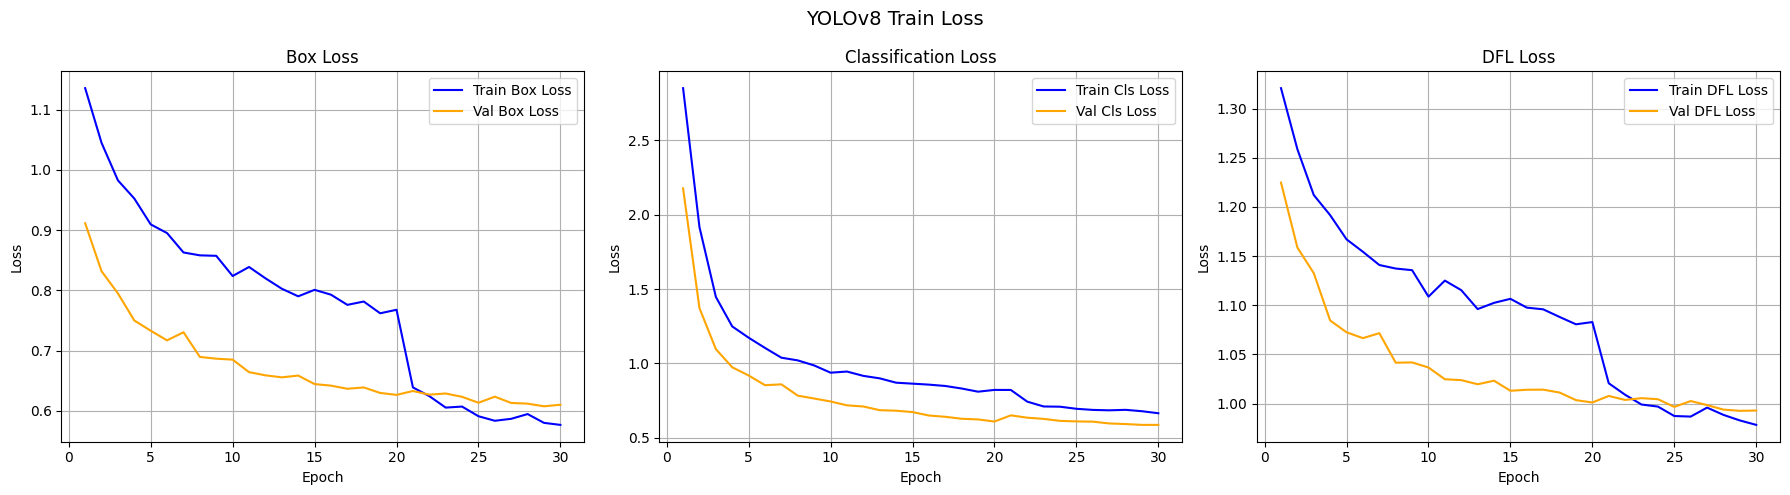

/tmp/ipykernel_534/365158529.py:77: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/365158529.py:77: UserWarning: Glyph 45733 (\N{HANGUL SYLLABLE NEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/365158529.py:77: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/365158529.py:77: UserWarning: Glyph 54364 (\N{HANGUL SYLLABLE PYO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45733 (\N{HANGUL SYLLABLE NEUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/d

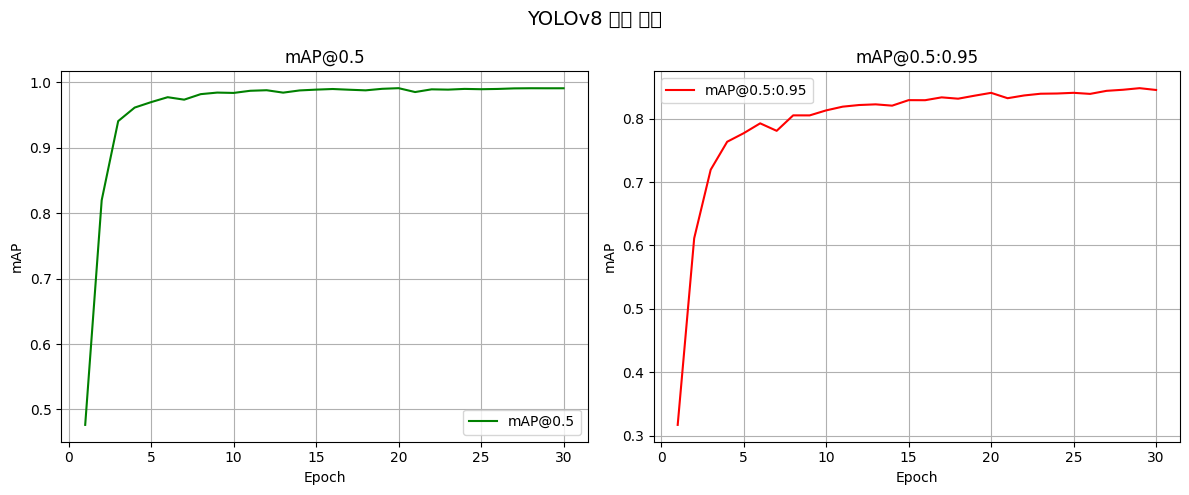

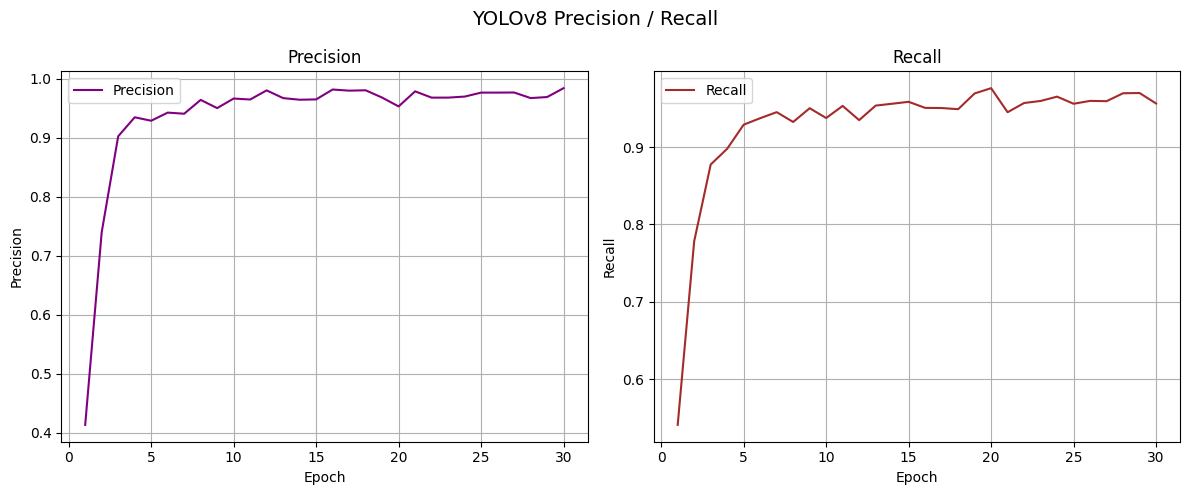


========== YOLOv8 최종 성능 요약 ==========
Best Epoch        : 20
mAP@0.5           : 0.9913
mAP@0.5:0.95      : 0.8406
Precision         : 0.9530
Recall            : 0.9762


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# -----------------------------
# 1) results.csv 로드
# -----------------------------
results_csv_path = "/content/yolo_runs/pet_detection/results.csv"

df = pd.read_csv(results_csv_path)
df.columns = df.columns.str.strip()  # 컬럼명 공백 제거

print("✅ results.csv 로드 완료!")
print(f"컬럼 목록: {df.columns.tolist()}")
print(df.head())


# -----------------------------
# 2) 학습 Loss 시각화
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("YOLOv8 Train Loss", fontsize=14)

# Box Loss
axes[0].plot(df["epoch"], df["train/box_loss"], label="Train Box Loss", color="blue")
axes[0].plot(df["epoch"], df["val/box_loss"],   label="Val Box Loss",   color="orange")
axes[0].set_title("Box Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Class Loss
axes[1].plot(df["epoch"], df["train/cls_loss"], label="Train Cls Loss", color="blue")
axes[1].plot(df["epoch"], df["val/cls_loss"],   label="Val Cls Loss",   color="orange")
axes[1].set_title("Classification Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

# DFL Loss
axes[2].plot(df["epoch"], df["train/dfl_loss"], label="Train DFL Loss", color="blue")
axes[2].plot(df["epoch"], df["val/dfl_loss"],   label="Val DFL Loss",   color="orange")
axes[2].set_title("DFL Loss")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()


# -----------------------------
# 3) 성능 지표 시각화 (mAP)
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("YOLOv8 성능 지표", fontsize=14)

# mAP@0.5
axes[0].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP@0.5", color="green")
axes[0].set_title("mAP@0.5")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("mAP")
axes[0].legend()
axes[0].grid(True)

# mAP@0.5:0.95
axes[1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP@0.5:0.95", color="red")
axes[1].set_title("mAP@0.5:0.95")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mAP")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# -----------------------------
# 4) Precision / Recall 시각화
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("YOLOv8 Precision / Recall", fontsize=14)

# Precision
axes[0].plot(df["epoch"], df["metrics/precision(B)"], label="Precision", color="purple")
axes[0].set_title("Precision")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Precision")
axes[0].legend()
axes[0].grid(True)

# Recall
axes[1].plot(df["epoch"], df["metrics/recall(B)"], label="Recall", color="brown")
axes[1].set_title("Recall")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Recall")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# -----------------------------
# 5) 최종 성능 요약 출력
# -----------------------------
best_epoch = df["metrics/mAP50(B)"].idxmax()
best_row   = df.loc[best_epoch]

print("\n========== YOLOv8 최종 성능 요약 ==========")
print(f"Best Epoch        : {int(best_row['epoch'])}")
print(f"mAP@0.5           : {best_row['metrics/mAP50(B)']:.4f}")
print(f"mAP@0.5:0.95      : {best_row['metrics/mAP50-95(B)']:.4f}")
print(f"Precision         : {best_row['metrics/precision(B)']:.4f}")
print(f"Recall            : {best_row['metrics/recall(B)']:.4f}")
print("============================================")

✅ Best 모델 로드 완료: /content/yolo_runs/pet_detection/weights/best.pt
=== Validation 샘플 ===
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]


/tmp/ipykernel_534/1385819460.py:78: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/1385819460.py:78: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/1385819460.py:78: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_534/1385819460.py:78: UserWarning: Glyph 44284 (\N{HANGUL SYLLABLE GWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/di

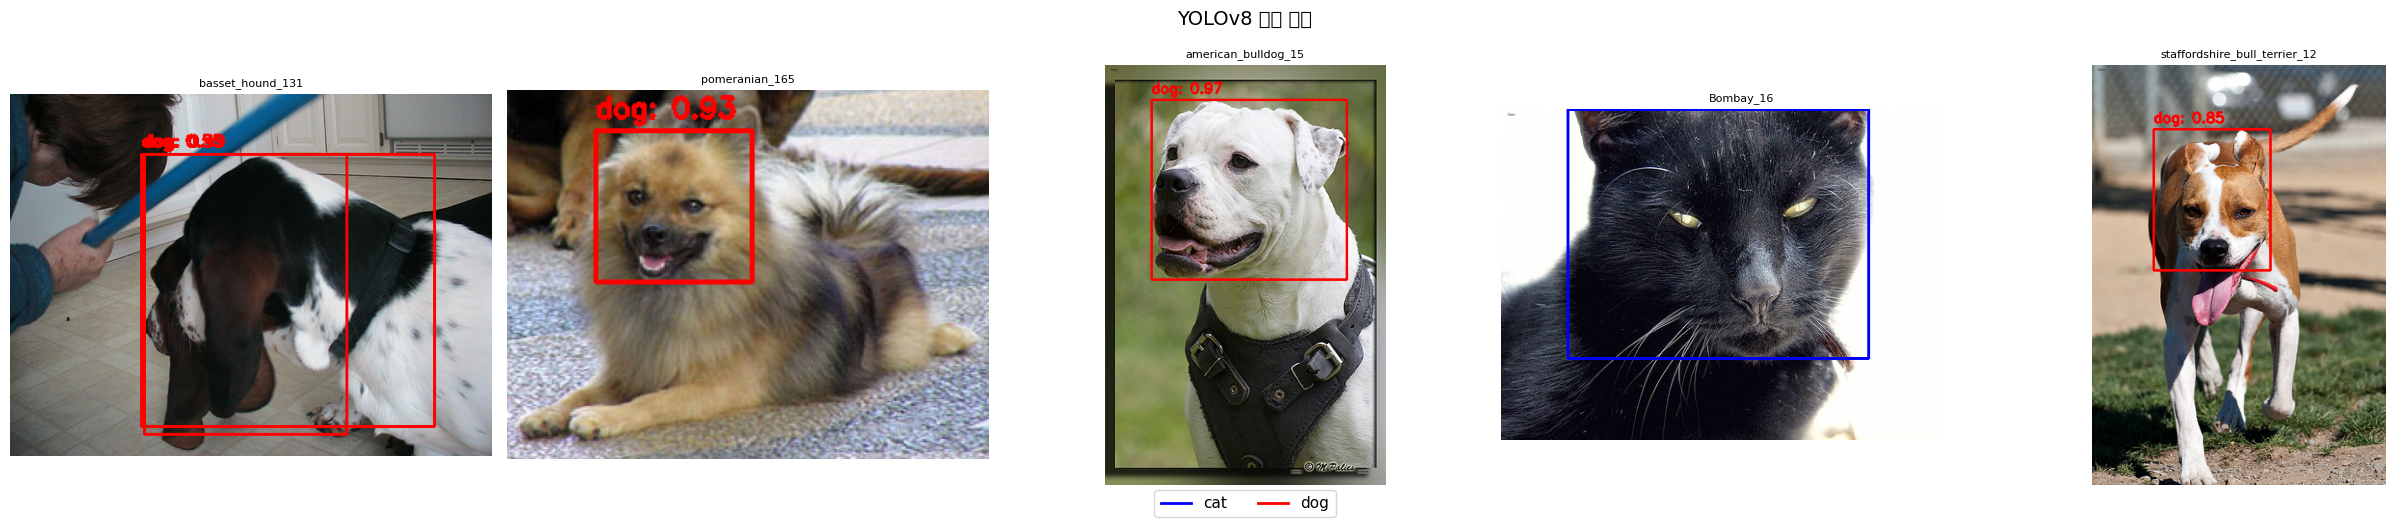

=== Test 샘플 ===
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]
WARNING ⚠️ imgsz=[300] must be multiple of max stride 32, updating to [320]


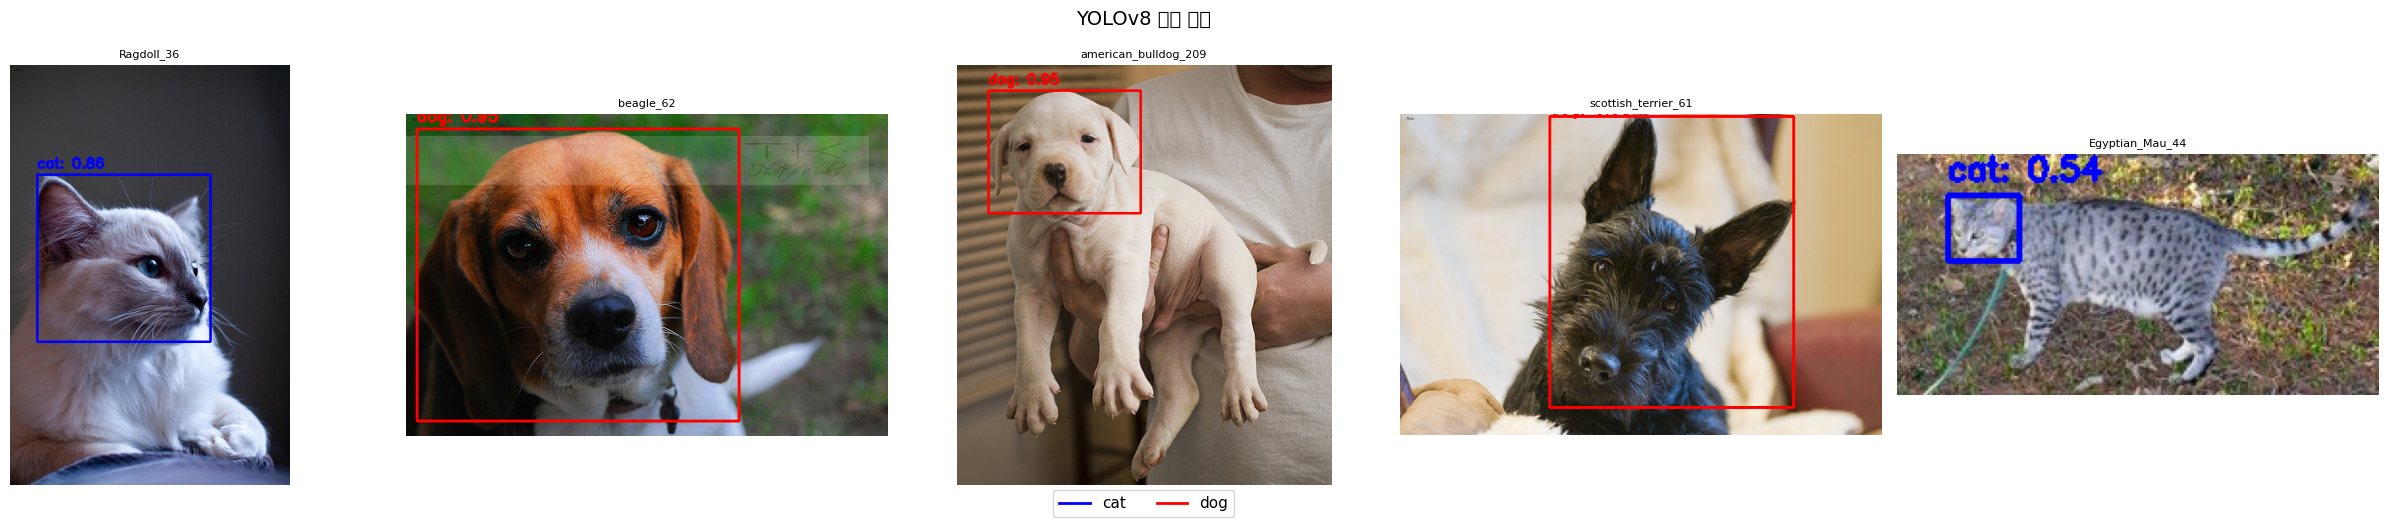

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
import numpy as np
import random

# -----------------------------
# 1) Best 모델 로드
# -----------------------------
best_model_path = "/content/yolo_runs/pet_detection/weights/best.pt"
yolo_best = YOLO(best_model_path)

print(f"✅ Best 모델 로드 완료: {best_model_path}")


# -----------------------------
# 2) 예측 시각화 함수
# -----------------------------
def visualize_yolo_predictions(model, image_dir, image_list, yolo_classes,
                                num_images=5, score_threshold=0.3, seed=42):
    random.seed(seed)
    sample_ids = random.sample(image_list, num_images)

    fig, axes = plt.subplots(1, num_images, figsize=(5 * num_images, 5))
    if num_images == 1:
        axes = [axes]

    class_colors = {
        "cat": (0, 0, 255),    # 파란색
        "dog": (255, 0, 0),    # 빨간색
    }

    for i, image_id in enumerate(sample_ids):
        image_path = os.path.join(image_dir, f"{image_id}.jpg")

        # 원본 이미지 로드
        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_vis = img.copy()

        # YOLO 예측
        results = model.predict(
            source=image_path,
            imgsz=300,
            conf=score_threshold,
            verbose=False
        )[0]

        # 예측 bbox 그리기
        for box in results.boxes:
            cls_idx  = int(box.cls.item())
            score    = float(box.conf.item())
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

            class_name = yolo_classes[cls_idx]
            color = class_colors.get(class_name, (0, 255, 0))

            cv2.rectangle(img_vis, (x1, y1), (x2, y2), color, 2)
            label = f"{class_name}: {score:.2f}"
            cv2.putText(img_vis, label, (x1, max(y1-8, 0)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)

        axes[i].imshow(img_vis)
        axes[i].axis("off")
        axes[i].set_title(f"{image_id}", fontsize=8)

    # 범례
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color="blue",  linewidth=2, label="cat"),
        Line2D([0], [0], color="red",   linewidth=2, label="dog"),
    ]
    fig.legend(handles=legend_elements, loc="lower center",
               ncol=2, fontsize=11, bbox_to_anchor=(0.5, -0.05))

    plt.suptitle("YOLOv8 예측 결과", fontsize=14)
    plt.tight_layout()
    plt.show()


# -----------------------------
# 3) Val / Test 샘플 시각화
# -----------------------------
print("=== Validation 샘플 ===")
visualize_yolo_predictions(
    model=yolo_best,
    image_dir=image_dir,
    image_list=valid_list,
    yolo_classes=yolo_classes,
    num_images=5,
    score_threshold=0.3
)

print("=== Test 샘플 ===")
visualize_yolo_predictions(
    model=yolo_best,
    image_dir=image_dir,
    image_list=test_list,
    yolo_classes=yolo_classes,
    num_images=5,
    score_threshold=0.3
)

항목값Best Epoch20 / 30

조기 종료 patience=10

mAP@0.5 0.991   3IoU 0.5 기준 99.1% 정확도

mAP@0.5:0.95    0.8406  엄격한 기준에서도 84%

Precision   0.9530  예측 중 95.3%가 정답

Recall  0.9762  실제 객체의 97.6% 탐지


------------


Val 샘플: cat/dog 모두 얼굴 영역을 정확하게 탐지

Test 샘플: 다양한 각도/조명에서도 안정적으로 탐지

confidence score가 대부분 0.9 이상으로 높은 신뢰도

## 7. 프로젝트 종합 평가 ##


### 7-1. 데이터셋 구성 ###

| 구분 | 수량 |
|------|------|
| Train | 2,569개 |
| Validation | 1,102개 |
| Test | 3,669개 |
| 전체 클래스 | cat, dog (2종) |

- Train/Validation은 전체 trainval 데이터(3,671개)를 **70:30 비율**로 분리
- XML annotation이 없는 **9개 이미지 제거** 후 사용
- Bounding Box는 **얼굴(Face) 영역** 기준

---

### 7-2. 전처리 및 데이터 증강 ###

#### 7-2-1. 전처리
- XML 파싱 (`xml.etree.ElementTree`) → Bounding Box 및 클래스 정보 추출
- `tv_tensors.BoundingBoxes` 적용 → 이미지 변환 시 Bounding Box 좌표 자동 조정
- **Letterbox Resize** (비율 유지 + 패딩) → 300x300 고정 크기로 변환

#### 7-2-2. 데이터 증강 (Train 전용)
| 기법 | 설명 |
|------|------|
| RandomHorizontalFlip (p=0.5) | 좌우 반전, Bounding Box 자동 반영 |
| RandomPhotometricDistort | 밝기/대비/채도/색조 랜덤 왜곡 |
| ColorJitter | 밝기/대비/채도/색조 미세 조정 |

---

### 7-3. 모델 구성 ###

#### 7-3-1. SSD300 (VGG16 Backbone)
- Backbone: VGG16 (COCO 사전학습 가중치)
- Classification Head를 cat/dog에 맞게 교체 (num_classes=3, background 포함)
- Optimizer: SGD (lr=0.001, momentum=0.9, weight_decay=5e-4)
- Scheduler: StepLR (step_size=10, gamma=0.1)
- Epochs: 30 (Best Model: 11 epoch)

#### 7-3-2. YOLOv8n (전이학습)
- 사전학습 모델: yolov8n.pt (COCO 사전학습)
- Optimizer: SGD (lr=0.001, momentum=0.9, weight_decay=5e-4)
- Epochs: 30 (Early Stopping patience=10 → 20 epoch에서 조기 종료)
- YOLO 내장 증강 (Mosaic, HSV, RandomFlip 등) 추가 적용
- XML → TXT 변환 후 yaml 설정 파일 작성하여 학습 진행

---

### 7-4. 성능 평가 결과 ###

#### 7-4-1. SSD300 성능

| 클래스 | AP |
|--------|------|
| cat | 0.9091 |
| dog | 0.9073 |
| **mAP@0.5** | **0.9082** |

#### 7-4-2. YOLOv8n 성능

| 지표 | 값 |
|------|-----|
| mAP@0.5 | 0.9913 |
| mAP@0.5:0.95 | 0.8406 |
| Precision | 0.9530 |
| Recall | 0.9762 |
| Best Epoch | 20 |

#### 7-4-3. 모델 비교

| 모델 | mAP@0.5 | Best Epoch | 비고 |
|------|---------|------------|------|
| SSD300 (VGG16) | 0.9082 | 11 | Head만 교체하여 전이학습 |
| YOLOv8n | **0.9913** | 20 | 전체 전이학습 + 내장 증강 |

---

### 7-5. 결론 및 분석 ###

#### 7-5-1. 성능 분석
- YOLOv8n이 SSD300 대비 **약 8.3%p 높은 mAP@0.5** 달성
- SSD300은 30 epoch 학습 시 **Best Model이 11 epoch**에서 나왔으며, 이후 Val Loss가 상승하는 전형적인 과적합 패턴 확인
- SSD300의 5 epoch(0.9079)과 30 epoch(0.9082) 간 mAP 차이가 **0.0003**에 불과하여, 이미 초기에 대부분의 학습이 완료되었음을 확인
- YOLOv8n은 **Early Stopping** 덕분에 20 epoch에서 조기 종료되어 과적합 없이 높은 성능 달성

#### 7-5-2. 전처리/증강 효과
- `tv_tensors.BoundingBoxes` 활용으로 이미지 변환 시 Bounding Box 좌표가 **자동으로 동일 비율 조정**되어 안정적인 학습 가능
- **Letterbox Resize** 적용으로 이미지 비율 왜곡 없이 300x300 입력 크기 유지
- Train 전용 데이터 증강 적용으로 다양한 조명/각도 환경에서도 안정적인 탐지 성능 확인

#### 7-5-3. 한계 및 개선 방향
- SSD300은 11 epoch 이후 과적합이 시작되었으며, **Early Stopping** 적용 시 불필요한 학습을 줄일 수 있음
- YOLOv8 입력 크기를 300 대신 **320** 으로 설정하면 stride 경고 없이 더 안정적인 학습 가능
- 더 큰 모델 (yolov8s, yolov8m 등) 사용 시 추가 성능 향상 기대 가능
- 두 모델 모두 **mAP@0.5 기준 0.90 이상**을 달성하였으나, 더 엄격한 기준인 mAP@0.5:0.95 지표도 함께 측정하면 보다 정밀한 비교 가능